# Exploración y limpieza de datos FBref (Python)

Lee los CSV generados por el notebook de R (`data/raw/fbref_r/`), los inspecciona,
los limpia y hace algunas visualizaciones básicas.

Flujo: **inventario → inspección por archivo → limpieza → visualización**.
Ejecuta celda a celda; las de limpieza dependen de lo que veas en la inspección.

In [1]:
!py -m pip install -q pandas matplotlib seaborn

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

DATA_DIR = Path("data/raw/fbref_r")

## 1. Inventario: qué CSV hay

In [27]:
csvs = sorted(DATA_DIR.glob("*.csv"))
print(f"{len(csvs)} archivos en {DATA_DIR}:\n")
for f in csvs:
    kb = f.stat().st_size / 1024
    # contar filas sin cargar todo en memoria
    with open(f, encoding="utf-8") as fh:
        n = sum(1 for _ in fh) - 1
    print(f"  {f.name:<45} {n:>6} filas   {kb:>7.0f} KB")

22 archivos en data\raw\fbref_r:

  laliga_match_results.csv                        3420 filas       689 KB
  laliga_player_defense.csv                       4561 filas       666 KB
  laliga_player_keepers.csv                        343 filas        53 KB
  laliga_player_keepers_adv.csv                    343 filas        68 KB
  laliga_player_misc.csv                          4561 filas       662 KB
  laliga_player_passing.csv                       5130 filas      1011 KB
  laliga_player_passing_types.csv                 5127 filas       742 KB
  laliga_player_playing_time.csv                  6180 filas      1101 KB
  laliga_player_possession.csv                    4561 filas       801 KB
  laliga_player_shooting.csv                      5130 filas       826 KB
  laliga_player_standard.csv                      5130 filas       982 KB
  laliga_team_defense.csv                          320 filas        50 KB
  laliga_team_gca.csv                              320 filas        46 KB
  la

## 2. Cargar todo en un diccionario
`dfs["laliga_match_results"]` te da ese DataFrame. Así los tienes todos a mano.

In [28]:
dfs = {}
for f in csvs:
    try:
        dfs[f.stem] = pd.read_csv(f)
    except Exception as e:
        print(f"error cargando {f.name}: {e}")
print("cargados:", list(dfs.keys()))

cargados: ['laliga_match_results', 'laliga_player_defense', 'laliga_player_keepers', 'laliga_player_keepers_adv', 'laliga_player_misc', 'laliga_player_passing', 'laliga_player_passing_types', 'laliga_player_playing_time', 'laliga_player_possession', 'laliga_player_shooting', 'laliga_player_standard', 'laliga_team_defense', 'laliga_team_gca', 'laliga_team_keepers', 'laliga_team_keepers_adv', 'laliga_team_misc', 'laliga_team_passing', 'laliga_team_passing_types', 'laliga_team_playing_time', 'laliga_team_possession', 'laliga_team_shooting', 'laliga_team_standard']


## 3. Análisis por tabla

In [29]:
def analizar(nombre, df, max_unicos=15):
    print("=" * 100)
    print(f"### {nombre}  |  {df.shape[0]} filas x {df.shape[1]} cols")
    print("=" * 100)

    # --- head y tail ---
    print("\n--- HEAD ---")
    display(df.head(3))
    print("--- TAIL ---")
    display(df.tail(3))

    # --- resumen por columna: tipo, nulos, únicos ---
    resumen = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_nulos": df.isna().sum(),
        "pct_nulos": (df.isna().mean() * 100).round(1),
        "n_unicos": df.nunique(),
    })
    print("\n--- COLUMNAS (tipo, nulos, únicos) ---")
    display(resumen)

    # --- valores únicos: solo para columnas de baja cardinalidad ---
    # (imprimir los únicos de 'Player' o 'xG' no aporta; los de 'Pos', 'Comp', 'Squad' sí)
    print("--- VALORES ÚNICOS (columnas con pocos valores distintos) ---")
    for c in df.columns:
        nu = df[c].nunique(dropna=True)
        if nu <= max_unicos:
            print(f"  {c} ({nu}): {sorted(df[c].dropna().unique().tolist())}")

    # --- rango de temporadas si existe ---
    if "Season_End_Year" in df.columns:
        por_temp = df["Season_End_Year"].value_counts().sort_index()
        print(f"\n--- TEMPORADAS: {por_temp.index.min()}-{por_temp.index.max()} ---")
        print("  filas por temporada:", dict(por_temp))

    # --- duplicados por clave natural (jugador o equipo + temporada + squad) ---
    clave = [c for c in ["Season_End_Year", "Squad", "Player"] if c in df.columns]
    if clave:
        dup = df.duplicated(subset=clave).sum()
        print(f"\n--- DUPLICADOS por clave {clave}: {dup} ---")
        if dup:
            display(df[df.duplicated(subset=clave, keep=False)].sort_values(clave).head(6))
    print("\n")

for nombre, df in dfs.items():
    analizar(nombre, df)

### laliga_match_results  |  3420 filas x 20 cols

--- HEAD ---


,Competition_Name,Gender,Country,Season_End_Year,Round,Wk,Day,Date,Time,Home,HomeGoals,Home_xG,Away,AwayGoals,Away_xG,Attendance,Venue,Referee,Notes,MatchURL
0,La Liga,M,ESP,2018,NaN,1,Fri,2017-08-18,20:15,Leganés,1.0,1.3,Alavés,0.0,1.1,9231.0,Estadio Municipal de Butarque,José Munuera,NaN,https://fbref.com/en/matches/5c28c716/Leganes-...
1,La Liga,M,ESP,2018,NaN,1,Fri,2017-08-18,22:15,Valencia,1.0,1.4,Las Palmas,0.0,0.2,35971.0,Estadio de Mestalla,Jesús Gil,NaN,https://fbref.com/en/matches/05e8105f/Valencia...
2,La Liga,M,ESP,2018,NaN,1,Sat,2017-08-19,18:15,Celta Vigo,2.0,1.8,Real Sociedad,3.0,2.1,16961.0,Estadio de Balaídos,Antonio Matéu Lahoz,NaN,https://fbref.com/en/matches/02357c77/Celta-Vi...


--- TAIL ---


,Competition_Name,Gender,Country,Season_End_Year,Round,Wk,Day,Date,Time,Home,HomeGoals,Home_xG,Away,AwayGoals,Away_xG,Attendance,Venue,Referee,Notes,MatchURL
3417,La Liga,M,ESP,2026,NaN,38,Sun,2026-05-24,NaN,Valencia,NaN,NaN,Barcelona,NaN,NaN,NaN,Estadio de Mestalla,NaN,NaN,https://fbref.com/en/stathead/matchup/teams/dc...
3418,La Liga,M,ESP,2026,NaN,38,Sun,2026-05-24,NaN,Girona,NaN,NaN,Elche,NaN,NaN,NaN,Estadi Municipal de Montilivi,NaN,NaN,https://fbref.com/en/stathead/matchup/teams/90...
3419,La Liga,M,ESP,2026,NaN,38,Sun,2026-05-24,NaN,Getafe,NaN,NaN,Osasuna,NaN,NaN,NaN,Coliseum Alfonso Pérez,NaN,NaN,https://fbref.com/en/stathead/matchup/teams/78...



--- COLUMNAS (tipo, nulos, únicos) ---


...

,Season_End_Year,Squad,Comp,Team_or_Opponent,Num_Players,Age,Poss,MP_Playing,Starts_Playing,Min_Playing,Mins_Per_90_Playing,Gls,Ast,G+A,G_minus_PK,PK,PKatt,CrdY,CrdR,PrgC_Progression,PrgP_Progression,Gls_Per,Ast_Per,G+A_Per,G_minus_PK_Per,G+A_minus_PK_Per,xG_Expected,npxG_Expected,xAG_Expected,npxG+xAG_Expected,xG_Per,xAG_Per,xG+xAG_Per,npxG_Per,npxG+xAG_Per,Url
317,2025,Valladolid,La Liga,opponent,26,27.1,56.7,9,99,810,9,18,13,31,18,0,0,24,1,141,374,2.00,1.44,3.44,2.00,3.44,16.7,16.7,12.5,29.2,1.86,1.38,3.24,1.86,3.24,https://fbref.com/en/squads/17859612/Valladoli...
318,2025,Villarreal,La Liga,team,23,27.8,43.1,9,99,810,9,15,13,28,15,0,2,28,1,158,343,1.67,1.44,3.11,1.67,3.11,15.1,13.3,11.5,24.8,1.67,1.28,2.95,1.48,2.76,https://fbref.com/en/squads/2a8183b3/Villarrea...
319,2025,Villarreal,La Liga,opponent,23,26.6,56.9,9,99,810,9,16,12,28,16,0,1,25,1,175,433,1.78,1.33,3.11,1.78,3.11,11.9,11.1,8.0,19.1,1.32,0.89,2.21,1.23,2.13,https://fbref.com/en/squads/2a8183b3/Villarrea...



--- COLUMNAS (tipo, nulos, únicos) ---


,dtype,n_nulos,pct_nulos,n_unicos
Season_End_Year,int64,0,0.0,8
Squad,str,0,0.0,29
Comp,str,0,0.0,1
Team_or_Opponent,str,0,0.0,2
Num_Players,int64,0,0.0,19
Age,float64,0,0.0,47
Poss,float64,0,0.0,171
MP_Playing,int64,0,0.0,2
Starts_Playing,int64,0,0.0,2
Min_Playing,int64,0,0.0,2


--- VALORES ÚNICOS (columnas con pocos valores distintos) ---
  Season_End_Year (8): [2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025]
  Comp (1): ['La Liga']
  Team_or_Opponent (2): ['opponent', 'team']
  MP_Playing (2): [9, 38]
  Starts_Playing (2): [99, 418]
  Min_Playing (2): [810, 3420]
  Mins_Per_90_Playing (2): [9, 38]
  PK (14): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 15]
  CrdR (15): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 15]

--- TEMPORADAS: 2018-2025 ---
  filas por temporada: {2018: np.int64(40), 2019: np.int64(40), 2020: np.int64(40), 2021: np.int64(40), 2022: np.int64(40), 2023: np.int64(40), 2024: np.int64(40), 2025: np.int64(40)}

--- DUPLICADOS por clave ['Season_End_Year', 'Squad']: 160 ---


,Season_End_Year,Squad,Comp,Team_or_Opponent,Num_Players,Age,Poss,MP_Playing,Starts_Playing,Min_Playing,Mins_Per_90_Playing,Gls,Ast,G+A,G_minus_PK,PK,PKatt,CrdY,CrdR,PrgC_Progression,PrgP_Progression,Gls_Per,Ast_Per,G+A_Per,G_minus_PK_Per,G+A_minus_PK_Per,xG_Expected,npxG_Expected,xAG_Expected,npxG+xAG_Expected,xG_Per,xAG_Per,xG+xAG_Per,npxG_Per,npxG+xAG_Per,Url
0,2018,Alavés,La Liga,team,30,25.5,40.3,38,418,3420,38,40,31,71,39,1,3,105,4,454,1045,1.05,0.82,1.87,1.03,1.84,38.5,36.1,27.7,63.8,1.01,0.73,1.74,0.95,1.68,https://fbref.com/en/squads/8d6fd021/2017-2018...
1,2018,Alavés,La Liga,opponent,30,26.8,59.7,38,418,3420,38,48,28,76,41,7,10,84,4,751,1842,1.26,0.74,2.00,1.08,1.82,55.9,48.6,38.8,87.4,1.47,1.02,2.49,1.28,2.30,https://fbref.com/en/squads/8d6fd021/2017-2018...
2,2018,Athletic Club,La Liga,team,26,26.7,49.6,38,418,3420,38,39,25,64,33,6,8,93,0,652,1519,1.03,0.66,1.68,0.87,1.53,49.7,43.8,33.7,77.5,1.31,0.89,2.19,1.15,2.04,https://fbref.com/en/squads/2b390eca/2017-2018...
3,2018,Athletic Club,La Liga,opponent,26,27.0,50.4,38,418,3420,38,46,33,79,43,3,6,106,8,666,1311,1.21,0.87,2.08,1.13,2.00,50.3,45.6,37.1,82.6,1.32,0.98,2.30,1.20,2.17,https://fbref.com/en/squads/2b390eca/2017-2018...
4,2018,Atlético Madrid,La Liga,team,26,26.6,47.5,38,418,3420,38,57,41,98,53,4,5,93,5,703,1460,1.50,1.08,2.58,1.39,2.47,50.2,46.3,36.6,82.9,1.32,0.96,2.28,1.22,2.18,https://fbref.com/en/squads/db3b9613/2017-2018...
5,2018,Atlético Madrid,La Liga,opponent,26,26.8,52.5,38,418,3420,38,21,17,38,20,1,4,98,0,737,1677,0.55,0.45,1.00,0.53,0.97,35.8,32.6,27.6,60.2,0.94,0.73,1.67,0.86,1.58,https://fbref.com/en/squads/db3b9613/2017-2018...


## 4. Inspección de un archivo
Cambia `KEY` por el que quieras mirar. Empieza por los resultados de partidos.

### Match Results

In [5]:
KEY = "laliga_match_results"   # cambia por cualquiera de la lista de arriba

df = dfs[KEY]
print("shape:", df.shape)
print("\ncolumnas:")
for c in df.columns:
    print("  ", repr(c), "->", df[c].dtype)
print("\nprimeras filas:")
df.head()

shape: (4560, 20)

columnas:
   'Competition_Name' -> str
   'Gender' -> str
   'Country' -> str
   'Season_End_Year' -> int64
   'Round' -> float64
   'Wk' -> int64
   'Day' -> str
   'Date' -> str
   'Time' -> str
   'Home' -> str
   'HomeGoals' -> float64
   'Home_xG' -> float64
   'Away' -> str
   'AwayGoals' -> float64
   'Away_xG' -> float64
   'Attendance' -> float64
   'Venue' -> str
   'Referee' -> str
   'Notes' -> float64
   'MatchURL' -> str

primeras filas:


,Competition_Name,Gender,Country,Season_End_Year,Round,Wk,Day,Date,Time,Home,HomeGoals,Home_xG,Away,AwayGoals,Away_xG,Attendance,Venue,Referee,Notes,MatchURL
0,La Liga,M,ESP,2015,NaN,1,Sat,2014-08-23,19:00,Málaga,1.0,NaN,Athletic Club,0.0,NaN,24500.0,Estadio La Rosaleda,Antonio Matéu Lahoz,NaN,https://fbref.com/en/matches/0b3ad7bb/Malaga-A...
1,La Liga,M,ESP,2015,NaN,1,Sat,2014-08-23,21:00,Granada,2.0,NaN,La Coruña,1.0,NaN,14800.0,Estadio Nuevo Los Cármenes,Iñaki Bikandi,NaN,https://fbref.com/en/matches/0bc81303/Granada-...
2,La Liga,M,ESP,2015,NaN,1,Sat,2014-08-23,21:00,Sevilla,1.0,NaN,Valencia,1.0,NaN,29352.0,Estadio Ramón Sánchez Pizjuán,Carlos del Cerro,NaN,https://fbref.com/en/matches/70778391/Sevilla-...
3,La Liga,M,ESP,2015,NaN,1,Sat,2014-08-23,23:00,Almería,1.0,NaN,Espanyol,1.0,NaN,12000.0,Estadio de los Juegos Mediterráneos,Alejandro Hernández,NaN,https://fbref.com/en/matches/1de2c4fe/Almeria-...
4,La Liga,M,ESP,2015,NaN,1,Sun,2014-08-24,19:00,Eibar,1.0,NaN,Real Sociedad,0.0,NaN,5173.0,Estadio Municipal de Ipurúa,Alfonso Álvarez,NaN,https://fbref.com/en/matches/1163cb1c/Eibar-Re...


In [6]:
df.tail()

,Competition_Name,Gender,Country,Season_End_Year,Round,Wk,Day,Date,Time,Home,HomeGoals,Home_xG,Away,AwayGoals,Away_xG,Attendance,Venue,Referee,Notes,MatchURL
4555,La Liga,M,ESP,2026,NaN,38,Sun,2026-05-24,NaN,Espanyol,NaN,NaN,Real Sociedad,NaN,NaN,NaN,RCDE Stadium,NaN,NaN,https://fbref.com/en/stathead/matchup/teams/e3...
4556,La Liga,M,ESP,2026,NaN,38,Sun,2026-05-24,NaN,Alavés,NaN,NaN,Rayo Vallecano,NaN,NaN,NaN,Estadio de Mendizorroza,NaN,NaN,https://fbref.com/en/stathead/matchup/teams/98...
4557,La Liga,M,ESP,2026,NaN,38,Sun,2026-05-24,NaN,Valencia,NaN,NaN,Barcelona,NaN,NaN,NaN,Estadio de Mestalla,NaN,NaN,https://fbref.com/en/stathead/matchup/teams/dc...
4558,La Liga,M,ESP,2026,NaN,38,Sun,2026-05-24,NaN,Girona,NaN,NaN,Elche,NaN,NaN,NaN,Estadi Municipal de Montilivi,NaN,NaN,https://fbref.com/en/stathead/matchup/teams/90...
4559,La Liga,M,ESP,2026,NaN,38,Sun,2026-05-24,NaN,Getafe,NaN,NaN,Osasuna,NaN,NaN,NaN,Coliseum Alfonso Pérez,NaN,NaN,https://fbref.com/en/stathead/matchup/teams/78...


In [7]:
# Resumen de nulos y tipos del archivo seleccionado
resumen = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_nulos": df.isna().sum(),
    "pct_nulos": (df.isna().mean() * 100).round(1),
    "n_unicos": df.nunique(),
})
resumen.sort_values("pct_nulos", ascending=False)

,dtype,n_nulos,pct_nulos,n_unicos
Notes,float64,4560,100.0,0
Round,float64,4560,100.0,0
Home_xG,float64,1479,32.4,53
Away_xG,float64,1479,32.4,45
Attendance,float64,829,18.2,3517
AwayGoals,float64,339,7.4,9
HomeGoals,float64,339,7.4,11
Referee,str,339,7.4,54
Time,str,290,6.4,33
Country,str,0,0.0,1


### laliga_player_standard

In [9]:
KEY = "laliga_player_standard"   # cambia por cualquiera de la lista de arriba

df = dfs[KEY]
print("shape:", df.shape)
print("\ncolumnas:")
for c in df.columns:
    print("  ", repr(c), "->", df[c].dtype)
print(df.shape)
print("\nprimeras filas:")
df.tail()

shape: (9501, 38)

columnas:
   'Season_End_Year' -> int64
   'Squad' -> str
   'Comp' -> str
   'Player' -> str
   'Nation' -> str
   'Pos' -> str
   'Age' -> str
   'Born' -> float64
   'MP_Playing' -> int64
   'Starts_Playing' -> int64
   'Min_Playing' -> int64
   'Mins_Per_90_Playing' -> float64
   'Gls' -> int64
   'Ast' -> float64
   'G+A' -> float64
   'G_minus_PK' -> int64
   'PK' -> int64
   'PKatt' -> float64
   'CrdY' -> int64
   'CrdR' -> int64
   'PrgC_Progression' -> float64
   'PrgP_Progression' -> float64
   'PrgR_Progression' -> float64
   'Gls_Per' -> float64
   'Ast_Per' -> float64
   'G+A_Per' -> float64
   'G_minus_PK_Per' -> float64
   'G+A_minus_PK_Per' -> float64
   'xG_Expected' -> float64
   'npxG_Expected' -> float64
   'xAG_Expected' -> float64
   'npxG+xAG_Expected' -> float64
   'xG_Per' -> float64
   'xAG_Per' -> float64
   'xG+xAG_Per' -> float64
   'npxG_Per' -> float64
   'npxG+xAG_Per' -> float64
   'Url' -> str
(9501, 38)

primeras filas:


,Season_End_Year,Squad,Comp,Player,Nation,Pos,Age,Born,MP_Playing,Starts_Playing,Min_Playing,Mins_Per_90_Playing,Gls,Ast,G+A,G_minus_PK,PK,PKatt,CrdY,CrdR,PrgC_Progression,PrgP_Progression,PrgR_Progression,Gls_Per,Ast_Per,G+A_Per,G_minus_PK_Per,G+A_minus_PK_Per,xG_Expected,npxG_Expected,xAG_Expected,npxG+xAG_Expected,xG_Per,xAG_Per,xG+xAG_Per,npxG_Per,npxG+xAG_Per,Url
9496,2026,Villarreal,La Liga,Alfonso Pedraza,ESP,"DF,MF",29-162,1996.0,2,0,21,0.2,0,0.0,0.0,0,0,0.0,1,0,3.0,0.0,7.0,0.00,0.00,0.00,0.00,0.00,0.1,0.1,0.0,0.1,0.25,0.00,0.25,0.25,0.25,https://fbref.com/en/players/63f04c6c/Alfonso-...
9497,2026,Villarreal,La Liga,Nicolas Pépé,CIV,"FW,MF",30-112,1995.0,4,4,290,3.2,2,1.0,3.0,2,0,0.0,0,0,23.0,23.0,35.0,0.62,0.31,0.93,0.62,0.93,1.9,1.9,1.1,2.9,0.58,0.33,0.91,0.58,0.91,https://fbref.com/en/players/57e3f0c7/Nicolas-...
9498,2026,Villarreal,La Liga,Ayoze Pérez,ESP,FW,32-051,1993.0,1,0,27,0.3,0,0.0,0.0,0,0,0.0,0,0,0.0,0.0,1.0,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.00,0.00,0.00,0.00,0.00,https://fbref.com/en/players/819aa8e7/Ayoze-Perez
9499,2026,Villarreal,La Liga,Yeremi Pino,ESP,"MF,FW",22-333,2002.0,2,2,159,1.8,0,1.0,1.0,0,0,0.0,0,0,6.0,18.0,18.0,0.00,0.57,0.57,0.00,0.57,0.2,0.2,0.9,1.0,0.09,0.48,0.57,0.09,0.57,https://fbref.com/en/players/540ec57b/Yeremi-Pino
9500,2026,Villarreal,La Liga,Renato Veiga,POR,DF,22-051,2003.0,3,1,141,1.6,0,0.0,0.0,0,0,0.0,1,0,2.0,3.0,1.0,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.0,0.01,0.00,0.01,0.01,0.01,https://fbref.com/en/players/fc8fcbd1/Renato-V...


In [19]:
df['Squad'].unique()

<ArrowStringArray>
[        'Almería',   'Athletic Club', 'Atlético Madrid',       'Barcelona',        'Espanyol',          'Getafe',       'La Coruña',        'Mallorca',          'Málaga',         'Osasuna',
     'Racing Sant',     'Real Madrid',         'Sevilla',  'Sporting Gijón',        'Tenerife',        'Valencia',      'Valladolid',      'Villarreal',           'Xerez',        'Zaragoza',
        'Hércules',         'Levante',   'Real Sociedad',           'Betis',         'Granada',  'Rayo Vallecano',      'Celta Vigo',           'Elche',         'Córdoba',           'Eibar',
      'Las Palmas',          'Alavés',         'Leganés',          'Girona',          'Huesca',           'Cádiz',          'Oviedo']
Length: 37, dtype: str

In [22]:
df.loc[(df['Squad'] == 'Celta Vigo') & (df['Season_End_Year'] == 2026), 'Player']

9172    Jones El-Abdellaoui
9173          Marcos Alonso
9174           Hugo Álvarez
9175             Iago Aspas
9176           Fran Beltrán
9177        Sergio Carreira
9178       Carlos Dominguez
9179            Pablo Durán
9180         Manu Fernández
9181         Borja Iglesias
9182          Ferran Jutglà
9183              Yoel Lago
9184         Óscar Mingueza
9185           Ilaix Moriba
9186             Ionuț Radu
9187         Mihailo Ristić
9188         Javi Rodríguez
9189           Miguel Román
9190    Javier Rueda Garcia
9191            Hugo Sotelo
9192          Carl Starfelt
9193       Williot Swedberg
9194         Bryan Zaragoza
Name: Player, dtype: str

In [10]:
import pandas as pd

# pl es tu DataFrame de laliga_player_standard (todas las temporadas 2016-2026)
df = df.copy()

# Age viene como texto ("28-045" = 28 años y 45 días en FBref). Sacamos los años.
df["Age_years"] = pd.to_numeric(df["Age"].astype(str).str.split("-").str[0], errors="coerce")

# Nation viene como "es ESP" (bandera + código). Nos quedamos con el código de 3 letras.
df["Nation_code"] = df["Nation"].astype(str).str.split().str[-1].replace("nan", pd.NA)

print("filas (jugador-temporada):", len(df))
print("temporadas:", sorted(df["Season_End_Year"].unique()))
print("jugadores únicos:", df["Player"].nunique())

filas (jugador-temporada): 9501
temporadas: [np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
jugadores únicos: 3003


In [11]:
# Un jugador puede aparecer en varias temporadas: contamos jugadores DISTINTOS por nación.
por_nacion = (
    df.dropna(subset=["Nation_code"])
      .groupby("Nation_code")["Player"]
      .nunique()
      .sort_values(ascending=False)
)
print("Nº de jugadores únicos por nacionalidad (top 20):")
print(por_nacion.head(20))
print(f"\nTotal nacionalidades distintas: {por_nacion.shape[0]}")

Nº de jugadores únicos por nacionalidad (top 20):
Nation_code
ESP    1537
ARG     197
BRA     129
FRA     102
POR      94
URU      67
MAR      48
COL      42
SRB      42
ITA      38
NED      33
CRO      29
GHA      29
SEN      28
NGA      28
CMR      28
CIV      24
CHI      24
MEX      24
BEL      23
Name: Player, dtype: int64

Total nacionalidades distintas: 108


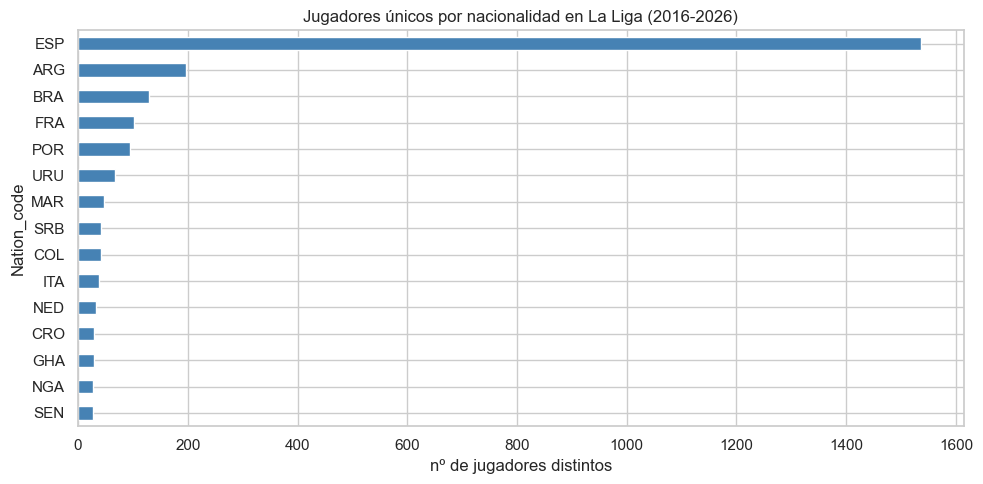

In [12]:
import matplotlib.pyplot as plt

top15 = por_nacion.head(15)
fig, ax = plt.subplots(figsize=(10, 5))
top15.sort_values().plot(kind="barh", ax=ax, color="steelblue")
ax.set_title("Jugadores únicos por nacionalidad en La Liga (2016-2026)")
ax.set_xlabel("nº de jugadores distintos")
plt.tight_layout()
plt.show()

In [13]:
# (a) Mejor temporada individual de xG
mejor_temp = df.loc[df["xG_Expected"].idxmax()]
print("--- Mayor xG en UNA temporada ---")
print(f'{mejor_temp["Player"]} ({mejor_temp["Squad"]}, {mejor_temp["Season_End_Year"]}): '
      f'{mejor_temp["xG_Expected"]:.1f} xG, {mejor_temp["Gls"]} goles')

# (b) xG acumulado en toda la historia (sumando todas sus temporadas)
acum = (
    df.groupby("Player")
      .agg(xG_total=("xG_Expected", "sum"),
           goles_total=("Gls", "sum"),
           temporadas=("Season_End_Year", "nunique"),
           minutos=("Min_Playing", "sum"))
      .sort_values("xG_total", ascending=False)
)
print("\n--- Top 10 xG acumulado 2016-2026 ---")
print(acum.head(10).round(1))

--- Mayor xG en UNA temporada ---
Lionel Messi (Barcelona, 2018): 27.1 xG, 34 goles

--- Top 10 xG acumulado 2016-2026 ---
                    xG_total  goles_total  temporadas  minutos
Player                                                        
Karim Benzema          114.5          238          14    31884
Iago Aspas             102.6          165          13    30248
Lionel Messi            92.4          420          12    34634
Gerard Moreno           92.0          121          12    23352
Luis Suárez             85.4          178           8    20233
Antoine Griezmann       84.1          198          16    40453
Iñaki Williams          78.7           82          12    28356
Mikel Oyarzabal         73.5           86          11    23222
Robert Lewandowski      70.7           71           4     8315
Ante Budimir            69.8           79           7    13614


In [14]:
# Goles - xG acumulado: positivo = mejor finalizador de lo esperado.
# Filtramos ruido: al menos 3000 minutos en total para que sea significativo.
fin = acum[acum["minutos"] >= 3000].copy()
fin["dif_gol_xg"] = fin["goles_total"] - fin["xG_total"]

print("--- Sobrerrendimiento (más goles que xG) ---")
print(fin.sort_values("dif_gol_xg", ascending=False).head(10)[["goles_total","xG_total","dif_gol_xg"]].round(1))
print("\n--- Infrarrendimiento (menos goles que xG) ---")
print(fin.sort_values("dif_gol_xg").head(10)[["goles_total","xG_total","dif_gol_xg"]].round(1))

--- Sobrerrendimiento (más goles que xG) ---
                   goles_total  xG_total  dif_gol_xg
Player                                              
Lionel Messi               420      92.4       327.6
Cristiano Ronaldo          311      25.2       285.8
Karim Benzema              238     114.5       123.5
Antoine Griezmann          198      84.1       113.9
Aritz Aduriz               125      16.0       109.0
Luis Suárez                178      85.4        92.6
Roberto Soldado            103      14.4        88.6
Álvaro Negredo              96      14.9        81.1
Rubén Castro                77       1.8        75.2
Gonzalo Higuaín             75       0.0        75.0

--- Infrarrendimiento (menos goles que xG) ---
                    goles_total  xG_total  dif_gol_xg
Player                                               
Nemanja Maksimović            9      17.9        -8.9
Jonathan Calleri             24      32.2        -8.2
Sergi Guardiola              24      32.1        -8.1
U

In [15]:
# Mejores creadores por xAG acumulado (asistencias esperadas)
creadores = (
    df.groupby("Player")["xAG_Expected"].sum()
      .sort_values(ascending=False).head(10)
)
print("--- Top creadores (xAG acumulado) ---")
print(creadores.round(1))

# Jugadores más jóvenes con impacto (xG+xAG por 90) con minutos suficientes en una temporada
jovenes = df[(df["Age_years"] <= 21) & (df["Min_Playing"] >= 1500)]
top_jovenes = jovenes.sort_values("npxG+xAG_Per", ascending=False).head(10)
print("\n--- Jóvenes (≤21) con más npxG+xAG por 90 (mín 1500 min en la temporada) ---")
print(top_jovenes[["Player","Squad","Season_End_Year","Age_years","npxG+xAG_Per"]].to_string(index=False))

--- Top creadores (xAG acumulado) ---
Player
Iago Aspas           56.6
Antoine Griezmann    54.4
Lionel Messi         53.2
Iñaki Williams       40.9
Karim Benzema        40.5
Vinicius Júnior      40.1
Gerard Moreno        39.6
Daniel Parejo        39.0
Luka Modrić          38.1
Jordi Alba           38.0
Name: xAG_Expected, dtype: float64

--- Jóvenes (≤21) con más npxG+xAG por 90 (mín 1500 min en la temporada) ---
          Player         Squad  Season_End_Year  Age_years  npxG+xAG_Per
         Rodrygo   Real Madrid             2023       21.0          0.75
    Lamine Yamal     Barcelona             2025       17.0          0.75
  Alexander Isak Real Sociedad             2021       20.0          0.68
 Vinicius Júnior   Real Madrid             2022       21.0          0.68
 Nicolas Jackson    Villarreal             2023       21.0          0.64
 Jude Bellingham   Real Madrid             2024       20.0          0.61
   Thierno Barry    Villarreal             2025       21.0          0.5

In [23]:
import pandas as pd

url = "https://raw.githubusercontent.com/JaseZiv/worldfootballR_data/master/raw-data/all_leages_and_cups/all_competitions.csv"
comps = pd.read_csv(url)

print("columnas:", list(comps.columns))
print("filas totales:", len(comps))
comps.head()

columnas: ['competition_type', 'competition_name', 'country', 'gender', 'governing_body', 'first_season', 'last_season', 'tier', 'awards', 'comp_url', 'seasons', 'season_end_year', 'seasons_urls', 'fixtures_url', 'is_completed', 'filter_out']
filas totales: 2344


,competition_type,competition_name,country,gender,governing_body,first_season,last_season,tier,awards,comp_url,seasons,season_end_year,seasons_urls,fixtures_url,is_completed,filter_out
0,Club International Cups,FIFA Club World Cup,NaN,M,FIFA,2019,2025,NaN,NaN,https://fbref.com/en/comps/719/history/FIFA-Cl...,2025,2025,https://fbref.com/en/comps/719/FIFA-Club-World...,https://fbref.com/en/comps/719/schedule/FIFA-C...,True,N
1,Club International Cups,FIFA Club World Cup,NaN,M,FIFA,2019,2025,NaN,NaN,https://fbref.com/en/comps/719/history/FIFA-Cl...,2023,2023,https://fbref.com/en/comps/719/2023/2023-FIFA-...,https://fbref.com/en/comps/719/2023/schedule/2...,True,N
2,Club International Cups,FIFA Club World Cup,NaN,M,FIFA,2019,2025,NaN,NaN,https://fbref.com/en/comps/719/history/FIFA-Cl...,2023,2023,https://fbref.com/en/comps/719/2022/2023-FIFA-...,https://fbref.com/en/comps/719/2022/schedule/2...,True,N
3,Club International Cups,FIFA Club World Cup,NaN,M,FIFA,2019,2025,NaN,NaN,https://fbref.com/en/comps/719/history/FIFA-Cl...,2022,2022,https://fbref.com/en/comps/719/2021/2022-FIFA-...,https://fbref.com/en/comps/719/2021/schedule/2...,True,N
4,Club International Cups,FIFA Club World Cup,NaN,M,FIFA,2019,2025,NaN,NaN,https://fbref.com/en/comps/719/history/FIFA-Cl...,2021,2021,https://fbref.com/en/comps/719/2020/2021-FIFA-...,https://fbref.com/en/comps/719/2020/schedule/2...,True,N


In [24]:
# ajusta los nombres de columna a los que veas en el head() de arriba
cols_liga = [c for c in comps.columns if c.lower() in
             ("country", "competition_name", "gender", "governing_body", "tier", "comp_name")]
print(comps[cols_liga].drop_duplicates().to_string())

                                                  competition_name country gender governing_body   tier
0                                              FIFA Club World Cup     NaN      M           FIFA    NaN
6                                     Copa Libertadores de América     NaN      M       CONMEBOL    NaN
18                                      Copa CONMEBOL Sudamericana     NaN      M       CONMEBOL    NaN
30                                           UEFA Champions League     NaN      M           UEFA    NaN
66                                              UEFA Europa League     NaN      M           UEFA    NaN
102                                         UEFA Conference League     NaN      M           UEFA    NaN
107                                                 UEFA Super Cup     NaN      M           UEFA    NaN
133                                  UEFA Women's Champions League     NaN      F           UEFA    NaN
145                                                 FIFA World C

In [25]:
# busca la columna de temporada
print([c for c in comps.columns if "season" in c.lower() or "year" in c.lower()])

# si existe 'season_end_year', temporadas por competición:
if "season_end_year" in comps.columns:
    resumen = (comps.groupby(["country", "competition_name"])["season_end_year"]
                    .agg(["min", "max", "nunique"])
                    .sort_values("nunique", ascending=False))
    print(resumen.to_string())

['first_season', 'last_season', 'seasons', 'season_end_year', 'seasons_urls']
                                                    min   max  nunique
country competition_name                                              
ENG     Premier League                             1889  2026      127
ESP     La Liga                                    1989  2026       38
ITA     Serie A                                    1989  2026       38
GER     Fußball-Bundesliga                         1989  2026       38
FRA     Ligue 1                                    1996  2026       31
USA     Major League Soccer                        1996  2025       30
GRE     Super League Greece                        2001  2026       26
POR     Primeira Liga                              2001  2026       26
NED     Eredivisie                                 2001  2026       26
NOR     Eliteserien                                2000  2025       26
SCO     Scottish Premiership                       2001  2026       26